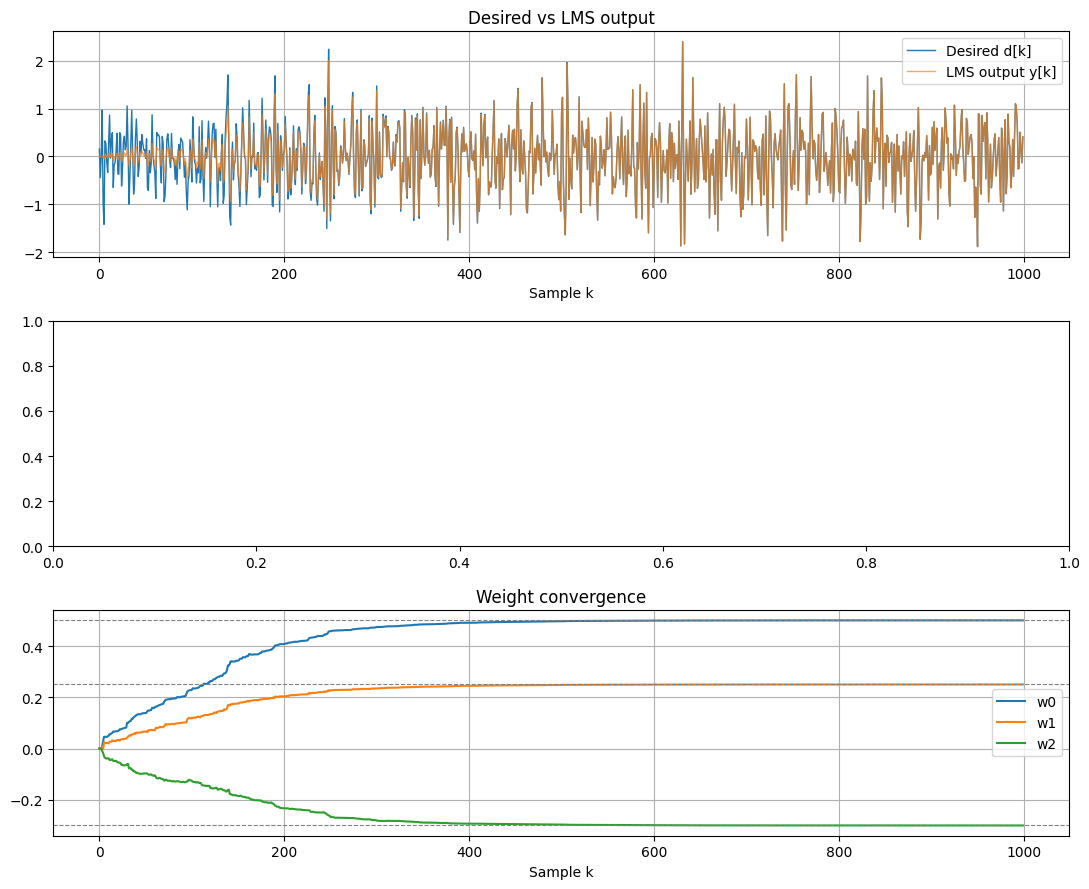

True coefficients:  [ 0.5   0.25 -0.3 ]
Estimated weights:  [ 0.49999107  0.2499886  -0.2999842 ]
Final weight error: 2.1429788004311747e-05


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# EXPERIMENT PARAMETERS
# ==========================================

N = 1000             # Number of samples
M = 3                # Number of LMS filter taps
mu = 0.005           # LMS step size

use_sinusoid = False # Add sinusoid to input
sin_freq = 0.02      # Normalized frequency (cycles/sample)
sin_amplitude = 1.0

noise_std = 1.0      # Input white noise standard deviation
seed = 42            # Reproducible experiment

# Unknown system coefficients
# h = np.array([0.5, -0.3, 0.2, 0.1, -0.1])
h = np.array([0.5, 0.25, -0.3])


# ==========================================
# GENERATE INPUT SIGNAL
# ==========================================

rng = np.random.default_rng(seed)
k = np.arange(N)

# Zero-mean white Gaussian noise
x = rng.normal(0, noise_std, N)

if use_sinusoid:
    x += sin_amplitude * np.sin(2 * np.pi * sin_freq * k)


# ==========================================
# UNKNOWN SYSTEM
# ==========================================

# Desired signal: output of unknown FIR system
d = np.convolve(x, h, mode="full")[:N]


# ==========================================
# LMS ALGORITHM
# ==========================================

w = np.zeros(M)           # Initial weights
y = np.zeros(N)           # Adaptive filter output
e = np.zeros(N)           # Error
w_history = np.zeros((N, M))

for k in range(M - 1, N):

    # Input vector: current and previous M-1 samples
    x_vec = x[k - M + 1:k + 1][::-1]

    # Adaptive filter output
    y[k] = np.dot(w, x_vec)

    # Error
    e[k] = d[k] - y[k]

    # Update weights
    w = w + 2 * mu * e[k] * x_vec

    # Store weights
    w_history[k] = w


# ==========================================
# PLOTS
# ==========================================

fig, axs = plt.subplots(3, 1, figsize=(11, 9))

# Desired vs estimated output
axs[0].plot(d, label="Desired d[k]", linewidth=1)
axs[0].plot(y, label="LMS output y[k]", linewidth=1, alpha=0.7)
axs[0].set_title("Desired vs LMS output")
axs[0].set_xlabel("Sample k")
axs[0].legend()
axs[0].grid(True)

# Error
axs[1].plot(e, linewidth=0.7)
axs[1].set_title("LMS error")
axs[1].set_xlabel("Sample k")
axs[1].grid(True)

# Weight convergence
for i in range(M):
    axs[2].plot(w_history[:, i], label=f"w{i}")

    if i < len(h):
        axs[2].axhline(h[i], linestyle="--",
                       linewidth=0.8, color="gray")

axs[2].set_title("Weight convergence")
axs[2].set_xlabel("Sample k")
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()

print("True coefficients: ", h)
print("Estimated weights: ", w)
print("Final weight error:", np.linalg.norm(w - np.pad(h, (0, max(0, M-len(h))))[:M]))
